# Assignment 4 - Knowledge Distillation and Hardware-Aware NAS
Edge Computing & Intelligent Systems

**Q1** - ResNet-50 teacher on CIFAR-100, three students (MobileNetV2, SqueezeNet, EfficientNet-Lite0) trained with and without knowledge distillation, ONNX export and ONNX Runtime CPU inference.
**Q2** - Optuna architecture search on CIFAR-10 under measured CPU latency / model-size limits, the best architecture trained from scratch, ONNX export and inference.

Every step is a standalone script; this notebook runs them in order and shows their output. Run all cells top to bottom.
A training step is skipped when its checkpoint already exists (its saved training log is shown instead); set `RETRAIN = True` to run everything again
(roughly 3 hours on a GPU).

On Windows, Jupyter shows the output of a script only when it finishes, so a long step can look idle while it runs.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import torch
from IPython.display import Image, display

RETRAIN = False   # True: retrain every stage

def run(script, *args, ckpt=None, log=None):
    """Run a script and show its output. A stage whose checkpoint exists is skipped (its saved log is shown)."""
    if ckpt and Path(ckpt).exists() and not RETRAIN:
        print(f"{ckpt} exists - skipped (set RETRAIN = True to retrain)")
        if log:
            print(pd.read_csv(log).dropna(subset=["test_acc"]).tail(5).to_string(index=False))
    else:
        get_ipython().system(f"{sys.executable} -u {script} {' '.join(args)}")

print("python :", sys.version.split()[0])
print("torch  :", torch.__version__, "| CUDA:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")

python : 3.11.14
torch  : 2.10.0+cu130 | CUDA: True | NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
# Are the datasets available? (a missing one is downloaded by the first script that needs it)
for name, folder in [("CIFAR-100", "data/cifar-100-python"), ("CIFAR-10", "data/cifar-10-batches-py")]:
    print(f"{name}:", "found in data/" if Path(folder).exists() else "missing - will be downloaded (about 170 MB) on first use")

CIFAR-100: found in data/
CIFAR-10: found in data/


## Q1.1 - Teacher: ResNet-50 on CIFAR-100

In [3]:
run("train_teacher.py", ckpt="checkpoints/teacher_resnet50.pth", log="results/log_teacher.csv")

checkpoints/teacher_resnet50.pth exists - skipped (set RETRAIN = True to retrain)
    tag  epoch  train_loss  test_acc
teacher     72      0.0331     78.61
teacher     74      0.0221     79.13
teacher     76      0.0176     79.31
teacher     78      0.0158     79.73
teacher     80      0.0152     79.71


## Q1.2 - Baseline students (plain cross-entropy, no distillation)

In [4]:
STUDENTS = ["mobilenetv2", "squeezenet", "efficientnet_lite0"]
for s in STUDENTS:
    run("train_baseline.py", "--student", s, ckpt=f"checkpoints/{s}_baseline.pth", log=f"results/log_{s}_baseline.csv")
    print()

checkpoints/mobilenetv2_baseline.pth exists - skipped (set RETRAIN = True to retrain)
                 tag  epoch  train_loss  test_acc
mobilenetv2_baseline     42      0.7881     67.91
mobilenetv2_baseline     44      0.6457     70.94
mobilenetv2_baseline     46      0.4977     72.45
mobilenetv2_baseline     48      0.3948     73.11
mobilenetv2_baseline     50      0.3518     73.51

checkpoints/squeezenet_baseline.pth exists - skipped (set RETRAIN = True to retrain)
                tag  epoch  train_loss  test_acc
squeezenet_baseline     42      1.1421     59.76
squeezenet_baseline     44      1.0104     63.81
squeezenet_baseline     46      0.8711     65.55
squeezenet_baseline     48      0.7657     66.60
squeezenet_baseline     50      0.7125     66.71

checkpoints/efficientnet_lite0_baseline.pth exists - skipped (set RETRAIN = True to retrain)
                        tag  epoch  train_loss  test_acc
efficientnet_lite0_baseline     42      0.7461     67.68
efficientnet_lite0_baselin

## Q1.3 - Knowledge distillation (soft targets with temperature + hard labels + feature distillation)

In [5]:
for s in STUDENTS:
    run("distill.py", "--student", s, ckpt=f"checkpoints/{s}_kd.pth", log=f"results/log_{s}_kd.csv")
    print()

checkpoints/mobilenetv2_kd.pth exists - skipped (set RETRAIN = True to retrain)
           tag  epoch  train_loss  test_acc
mobilenetv2_kd     42      2.2118     73.10
mobilenetv2_kd     44      1.9550     74.39
mobilenetv2_kd     46      1.7324     75.79
mobilenetv2_kd     48      1.6005     76.70
mobilenetv2_kd     50      1.5472     76.65

checkpoints/squeezenet_kd.pth exists - skipped (set RETRAIN = True to retrain)
          tag  epoch  train_loss  test_acc
squeezenet_kd     42      3.3669     61.75
squeezenet_kd     44      3.0784     64.91
squeezenet_kd     46      2.8110     67.41
squeezenet_kd     48      2.6334     68.13
squeezenet_kd     50      2.5340     68.11

checkpoints/efficientnet_lite0_kd.pth exists - skipped (set RETRAIN = True to retrain)
                  tag  epoch  train_loss  test_acc
efficientnet_lite0_kd     42      2.2508     71.91
efficientnet_lite0_kd     44      1.9677     73.95
efficientnet_lite0_kd     46      1.7326     75.76
efficientnet_lite0_kd     

### Training curves

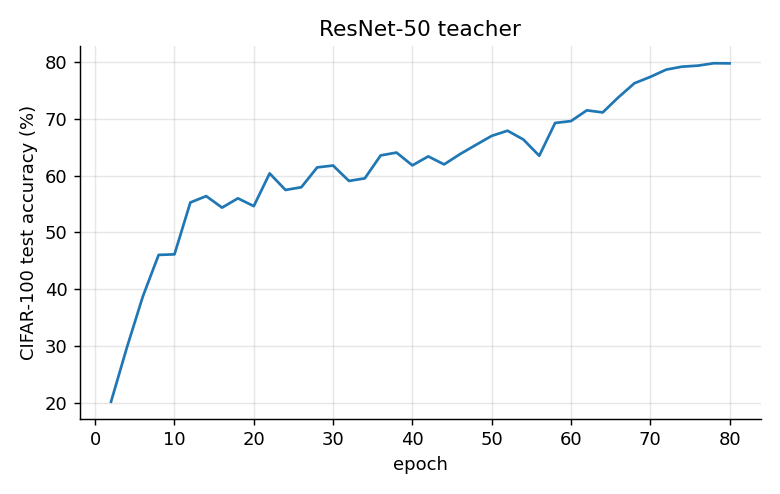

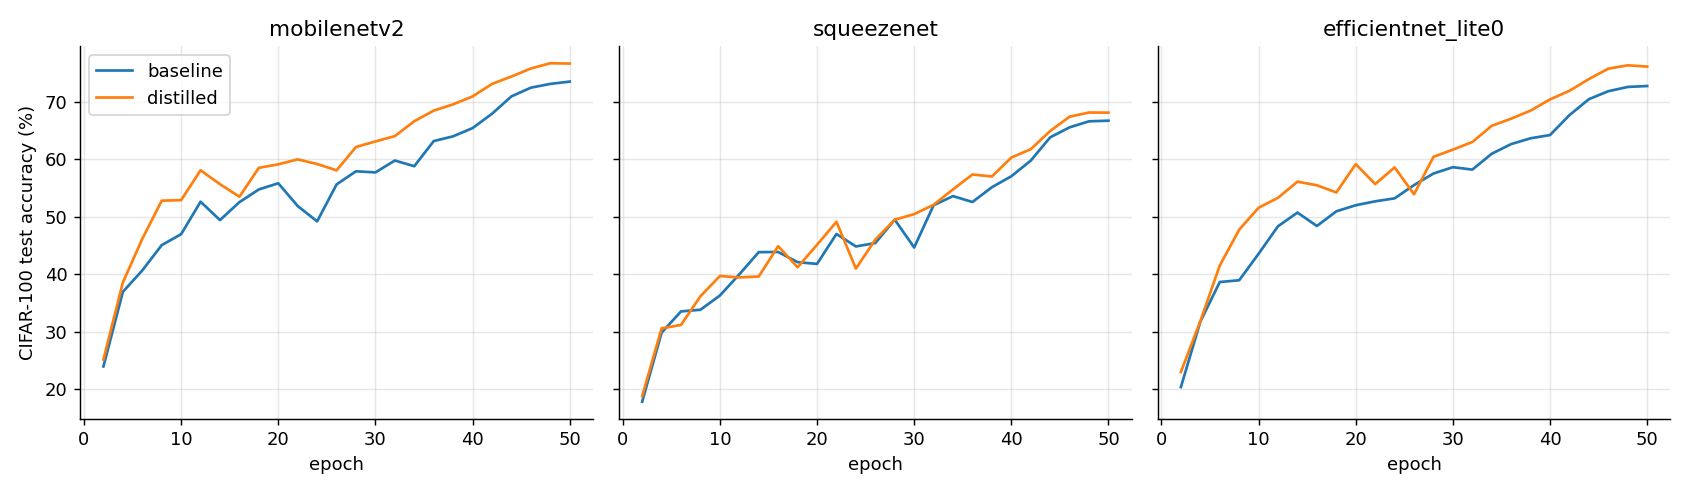

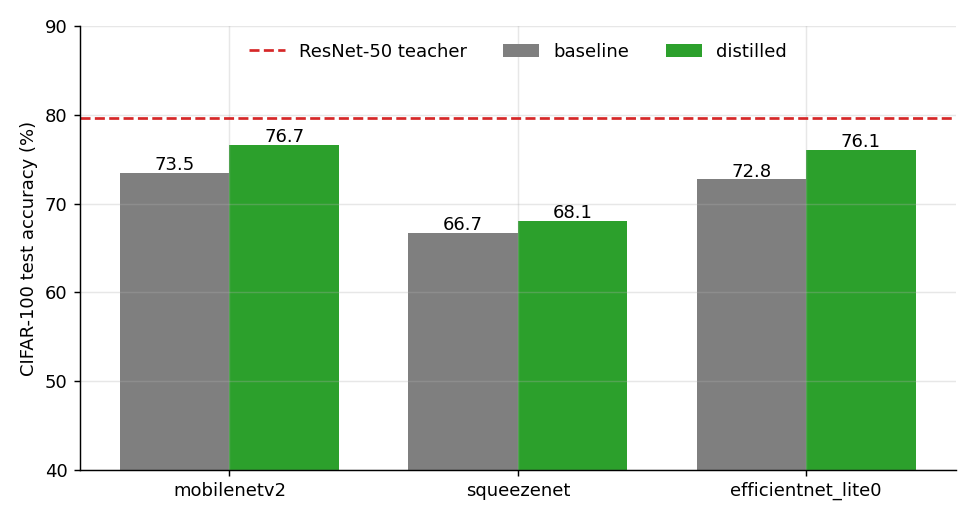

In [6]:
for f in ["fig_teacher_training", "fig_kd_vs_baseline_curves", "fig_accuracy_baseline_vs_kd"]:
    display(Image(f"results/graphs/{f}.png", width=800))

## Q1.4 - Unified inference pipeline (same script for every model)

In [7]:
run("inference.py", "--list")
for m in ["teacher_resnet50", "mobilenetv2_baseline", "mobilenetv2_kd", "squeezenet_kd", "efficientnet_lite0_kd"]:
    run("inference.py", "--model", m, "--n", "4")
    print()

available models: efficientnet_lite0_baseline, efficientnet_lite0_kd, mobilenetv2_baseline, mobilenetv2_kd, nas_best, squeezenet_baseline, squeezenet_kd, teacher_resnet50
teacher_resnet50: resnet50 trained on cifar100, test accuracy 79.71%
  image  5845   true: clock           predicted: clock           (100.0%)  ok
  image  4470   true: wolf            predicted: wolf            ( 99.9%)  ok
  image  9002   true: tiger           predicted: tiger           (100.0%)  ok
  image  5321   true: house           predicted: house           (100.0%)  ok

mobilenetv2_baseline: mobilenetv2 trained on cifar100, test accuracy 73.51%
  image  5845   true: clock           predicted: clock           (100.0%)  ok
  image  4470   true: wolf            predicted: wolf            ( 99.9%)  ok
  image  9002   true: tiger           predicted: tiger           (100.0%)  ok
  image  5321   true: house           predicted: house           (100.0%)  ok

mobilenetv2_kd: mobilenetv2 trained on cifar100, test accu

## Q2.1 to Q2.6 - Hardware-aware architecture search (Optuna TPE, CIFAR-10)
Every candidate is exported to ONNX and measured with ONNX Runtime on the CPU; candidates over the limits are rejected before training.

In [8]:
run("nas_search.py", "--trials", "60", "--epochs", "10", ckpt="results/nas_best.json")

results/nas_best.json exists - skipped (set RETRAIN = True to retrain)


In [9]:
import json
hist = pd.read_csv("results/nas_history.csv")
print(hist.status.value_counts().to_string(), "\n")
print("best architecture:")
print(json.dumps(json.load(open("results/nas_best.json")), indent=1))
hist.sort_values("val_acc", ascending=False).head(8)

status
ok          51
rejected     9 

best architecture:
{
 "trial": 20,
 "val_acc": 86.28,
 "limits": {
  "latency_ms": 1.5,
  "size_mb": 1.0
 },
 "hardware": {
  "latency_ms": 0.5607000000509288,
  "size_mb": 0.2301168441772461,
  "peak_rss_mb": 0.01953125,
  "act_mb": 0.75,
  "params": 60426.0
 },
 "config": {
  "resolution": 32,
  "stem": 32,
  "stages": [
   {
    "c": 96,
    "n": 2,
    "k": 3,
    "type": "dws",
    "act": "silu"
   },
   {
    "c": 96,
    "n": 2,
    "k": 5,
    "type": "dws",
    "act": "relu"
   },
   {
    "c": 64,
    "n": 3,
    "k": 5,
    "type": "dws",
    "act": "relu"
   }
  ]
 }
}


,trial,status,val_acc,latency_ms,size_mb,peak_rss_mb,act_mb,params
25,25,ok,86.42,0.84055,0.261684,0.019531,0.750,68714
26,26,ok,86.32,1.02150,0.201353,0.019531,0.375,52250
20,20,ok,86.28,0.56070,0.230117,0.019531,0.750,60426
24,24,ok,86.28,0.56935,0.230117,0.019531,0.750,60426
21,21,ok,86.10,0.57865,0.230117,0.019531,0.750,60426
23,23,ok,85.92,0.59275,0.230117,0.019531,0.750,60426
42,42,ok,85.88,0.53530,0.230117,0.019531,0.750,60426
22,22,ok,85.78,0.61140,0.230117,0.019531,0.750,60426


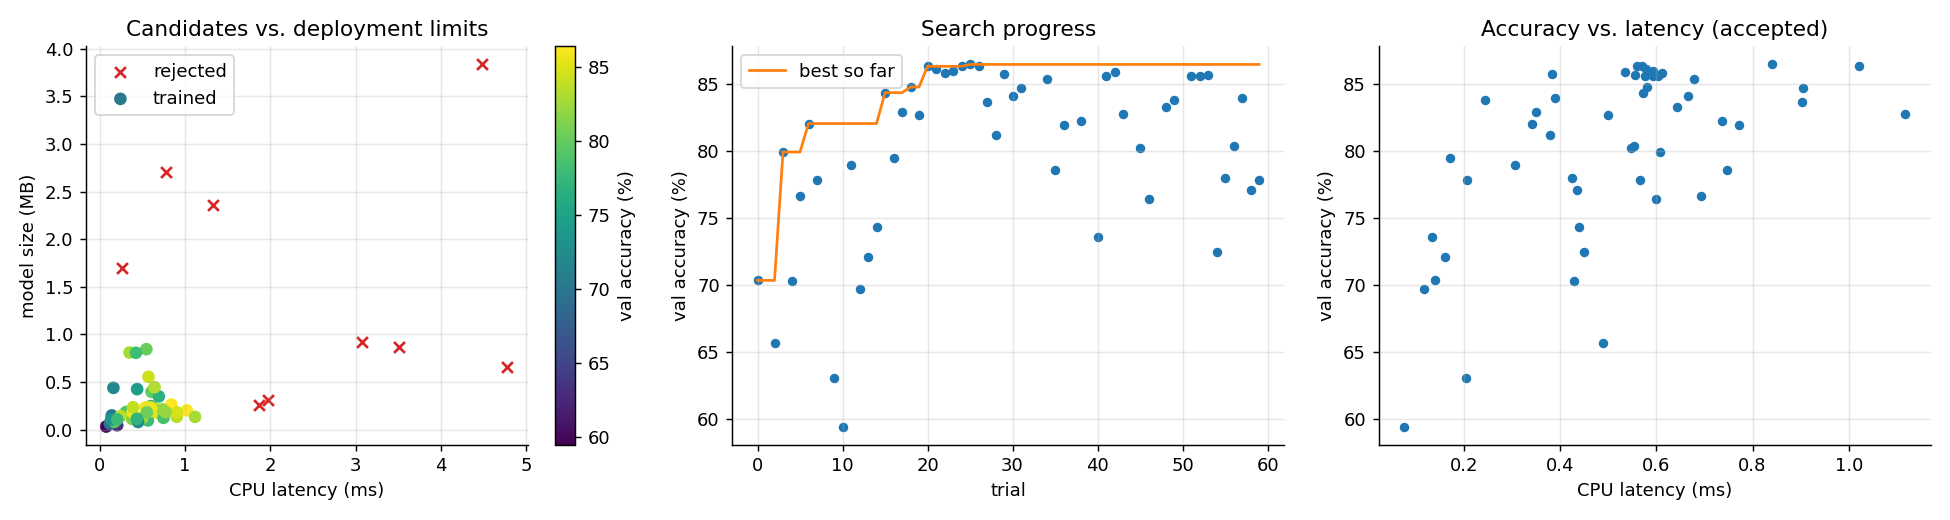

In [10]:
display(Image("results/graphs/fig_nas_search.png", width=900))

## Q2.7 - Train the best architecture from scratch

In [11]:
run("nas_final.py", ckpt="checkpoints/nas_best.pth", log="results/log_nas_best.csv")

checkpoints/nas_best.pth exists - skipped (set RETRAIN = True to retrain)
     tag  epoch  train_loss  test_acc
nas_best     80      0.1980     88.70
nas_best     85      0.1653     88.89
nas_best     90      0.1250     90.31
nas_best     95      0.0957     90.94
nas_best    100      0.0862     91.04


nas_best: nas trained on cifar10, test accuracy 91.04%
  image  5845   true: dog             predicted: dog             (100.0%)  ok
  image  4470   true: airplane        predicted: truck           ( 96.5%)  wrong
  image  9002   true: frog            predicted: frog            ( 91.9%)  ok
  image  5321   true: automobile      predicted: automobile      ( 99.8%)  ok
  image  1463   true: airplane        predicted: airplane        ( 98.6%)  ok


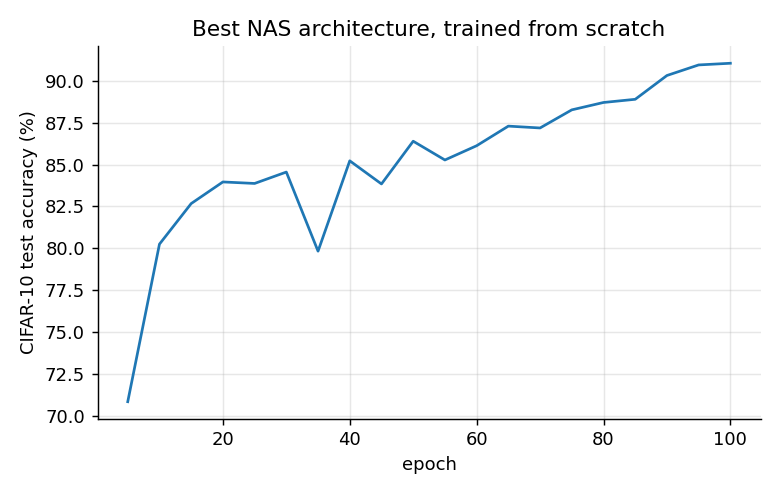

In [12]:
run("inference.py", "--model", "nas_best", "--n", "5")
display(Image("results/graphs/fig_nas_final_training.png", width=500))

## Q1.7 / Q2.8 - ONNX export and ONNX Runtime CPU inference

In [13]:
run("export_onnx.py")

efficientnet_lite0_baseline  -> efficientnet_lite0_baseline.onnx  13.30 MB   max |torch - onnx| = 2.4e-06
efficientnet_lite0_kd        -> efficientnet_lite0_kd.onnx    13.30 MB   max |torch - onnx| = 3.8e-06
mobilenetv2_baseline         -> mobilenetv2_baseline.onnx      8.94 MB   max |torch - onnx| = 5.7e-06
mobilenetv2_kd               -> mobilenetv2_kd.onnx            8.94 MB   max |torch - onnx| = 3.1e-06
nas_best                     -> nas_best.onnx                  0.23 MB   max |torch - onnx| = 6.2e-06
squeezenet_baseline          -> squeezenet_baseline.onnx       2.96 MB   max |torch - onnx| = 6.7e-06
squeezenet_kd                -> squeezenet_kd.onnx             2.96 MB   max |torch - onnx| = 7.2e-06


In [14]:
run("onnx_inference.py")

efficientnet_lite0_baseline  ONNX Runtime CPU: top-1 72.74%  latency 2.05 ms (1 thread)
    image 0: true mountain       predicted road
    image 1: true forest         predicted forest
    image 2: true seal           predicted otter
efficientnet_lite0_kd        ONNX Runtime CPU: top-1 76.12%  latency 1.95 ms (1 thread)
    image 0: true mountain       predicted road
    image 1: true forest         predicted forest
    image 2: true seal           predicted otter
mobilenetv2_baseline         ONNX Runtime CPU: top-1 73.50%  latency 1.87 ms (1 thread)
    image 0: true mountain       predicted palm_tree
    image 1: true forest         predicted forest
    image 2: true seal           predicted beaver
mobilenetv2_kd               ONNX Runtime CPU: top-1 76.65%  latency 1.85 ms (1 thread)
    image 0: true mountain       predicted road
    image 1: true forest         predicted forest
    image 2: true seal           predicted otter
nas_best                     ONNX Runtime CPU: top-1 9

## Benchmark - all models

In [15]:
run("benchmark.py")

{'model': 'teacher_resnet50', 'dataset': 'cifar100', 'top1': 79.71, 'top5': 95.18, 'params_M': 23.705, 'macs_M': 1298.0, 'checkpoint_MB': 45.41, 'act_mem_MB': 2.0, 'torch_cpu_ms': 80.282}
{'model': 'efficientnet_lite0_baseline', 'dataset': 'cifar100', 'top1': 72.75, 'top5': 93.18, 'params_M': 3.499, 'macs_M': 95.8, 'checkpoint_MB': 13.6, 'act_mem_MB': 0.75, 'torch_cpu_ms': 4.004, 'onnx_MB': 13.3, 'ort_cpu_ms': 1.806, 'ort_throughput_img_s': 558, 'peak_rss_MB': 0.04}
{'model': 'mobilenetv2_baseline', 'dataset': 'cifar100', 'top1': 73.51, 'top5': 93.52, 'params_M': 2.352, 'macs_M': 88.1, 'checkpoint_MB': 9.2, 'act_mem_MB': 1.125, 'torch_cpu_ms': 4.23, 'onnx_MB': 8.94, 'ort_cpu_ms': 1.608, 'ort_throughput_img_s': 589, 'peak_rss_MB': 0.02}
{'model': 'squeezenet_baseline', 'dataset': 'cifar100', 'top1': 66.73, 'top5': 90.31, 'params_M': 0.777, 'macs_M': 24.2, 'checkpoint_MB': 3.03, 'act_mem_MB': 0.5, 'torch_cpu_ms': 2.441, 'onnx_MB': 2.96, 'ort_cpu_ms': 0.389, 'ort_throughput_img_s': 2609, 

In [16]:
bench = pd.read_csv("results/benchmark.csv")
bench.set_index("model")

,dataset,top1,top5,params_M,macs_M,checkpoint_MB,act_mem_MB,torch_cpu_ms,onnx_MB,ort_cpu_ms,ort_throughput_img_s,peak_rss_MB
model,,,,,,,,,,,,
teacher_resnet50,cifar100,79.71,95.18,23.705,1298.0,45.41,2.000,80.282,NaN,NaN,NaN,NaN
efficientnet_lite0_baseline,cifar100,72.75,93.18,3.499,95.8,13.60,0.750,4.004,13.30,1.806,558.0,0.04
mobilenetv2_baseline,cifar100,73.51,93.52,2.352,88.1,9.20,1.125,4.230,8.94,1.608,589.0,0.02
squeezenet_baseline,cifar100,66.73,90.31,0.777,24.2,3.03,0.500,2.441,2.96,0.389,2609.0,0.02
efficientnet_lite0_kd,cifar100,76.12,94.73,3.499,95.8,13.60,0.750,3.986,13.30,1.814,571.0,0.02
mobilenetv2_kd,cifar100,76.66,94.86,2.352,88.1,9.20,1.125,4.279,8.94,1.576,600.0,0.02
nas_best,cifar10,91.04,99.80,0.060,21.9,0.27,0.750,1.408,0.23,0.528,1639.0,0.02
squeezenet_kd,cifar100,68.10,90.94,0.777,24.2,3.03,0.500,2.456,2.96,0.395,2630.0,0.02


figures saved to results/graphs/


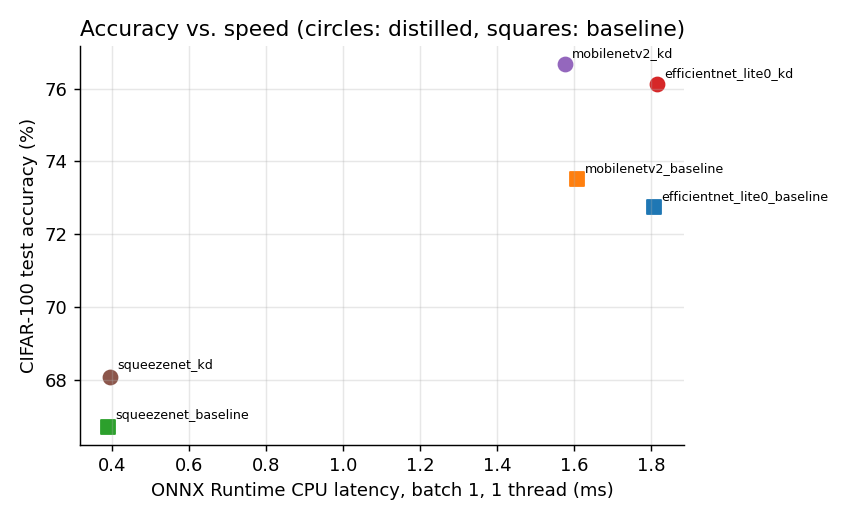

In [17]:
run("make_plots.py")
display(Image("results/graphs/fig_accuracy_vs_latency.png", width=650))